## Read the data

In [1]:
import numpy as np
import pandas as pd
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"

In [2]:
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/per_length_per_kfold_split/' # windows
# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu
TARGET_PATH_TO_RESULTS = "experiment_results/retrained_models/"
RUNS = 15
TOTAL_SPLITS = 1

# Read models

In [3]:
MODELS_DESCRIPTIONS = {
    "viterbi_simple_with_pseudo_and_weights_7": {
        "path": "experiment_results/core_finding_models_viterbi_simple_with_pseudo/",
        "states": 7,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01',
                    # 'HLA-DPA1*01:03-DPB1*04:01'
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [12, 13, 14, 15, 16, 17, 18],
        "core_start_state": 7,
        "core_end_state": 8

    },
    "viterbi_with_pseudo_and_weights_7": {
        "path": "experiment_results/core_finding_models_viterbi_simple_with_pseudo/",
        "states": 35,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01',
                    # 'HLA-DPA1*01:03-DPB1*04:01'
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [12, 13, 14, 15, 16, 17, 18],
        "core_start_state": [35],
        "core_end_state": [36],
        "need_to_delete": [37, 38]

    },
    "viterbi_multiple_7": {
        "path": "experiment_results/core_multiple_allele/",
        "states": 35,
        "params_string": "30-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-DRB1*01:01',
                    'HLA-DPA1*01:03/DPB1*04:01'
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [12, 13, 14, 15, 16, 17, 18],
        "core_start_state": [35, 36],
        "core_end_state": [37, 38],
        "need_to_delete": [39, 40, 41, 42]

    }



    # "mix_of_alleles_balanced":
    # {
    #     "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
    #     "path": "experiment_results/alleles_with_groups_balanced/",
    #     "states": 25,
    #     "params_string": "5-min_iters",
    #     "target_lengths": [9, 10]
    # }
}

In [4]:
selected_models = [
     "viterbi_with_pseudo_and_weights_7"
]
models_to_read = ["v"]

In [5]:
from hmm_logic_methods import load_model

In [6]:
import itertools

name_to_run = dict()
name_to_split = dict()
name_to_type = dict()
name_to_model_root = dict()
name_to_target_lengths = dict()
selected_binding_models = list()
per_name_models = dict()


def populate_models_infos(model_name, run_num, split_num, model_path, model_type, target_lengths ):
    selected_binding_models.append(model_name)

    name_to_run[model_name] = run_num
    name_to_split[model_name] = split_num
    name_to_model_root[model_name] = model_path
    assert model_type in ["bw", "v", "bwv", "bw-it", "bwv-it", "v-it"] or "mixed" in model_type
    name_to_type[model_name] = model_type
    name_to_target_lengths[model_name] = target_lengths

for model in selected_models:
    model_description = MODELS_DESCRIPTIONS[model]
    combination_size = model_description['combination_size']
    model_alleles = model_description['alleles']
    MODELS_PATH = model_description['path']
    params_string = model_description['params_string']
    states = model_description['states']
    TARGET_LENGTHS = model_description['target_lengths']
    target_length_string = "-".join([str(l) for l in TARGET_LENGTHS])
    MIXED_ALLELES = list()

    for combination in itertools.combinations(sorted(model_alleles), combination_size):
        allele_name = "+".join(combination)
        # allele_name = f"{allele_name1}+{allele_name2}"
        MIXED_ALLELES.append(allele_name)

    for allele_name in MIXED_ALLELES:
        target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_').replace('/', '_')
        for run_num_b in range(RUNS):
            for split_num_b in range(TOTAL_SPLITS):
                #bw
                if 'bw' in models_to_read:
                    bw_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-{params_string}_model-{target_allele_name}-{split_num_b}"
                    print(bw_model_name)
                    populate_models_infos(bw_model_name, run_num_b,split_num_b, MODELS_PATH, f"bw-it-mixed({target_allele_name})", TARGET_LENGTHS)
                if 'bwv' in models_to_read:
                    #bwv
                    bwv_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-{params_string}_model-{target_allele_name}-{split_num_b}_plus_viterbi"
                    populate_models_infos(bwv_model_name, run_num_b,split_num_b, MODELS_PATH, f"bwv-it-mixed({target_allele_name})", TARGET_LENGTHS)
                if 'v' in models_to_read:
                    #v
                    v_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-viterbi-alg-{params_string}_model-{target_allele_name}-{split_num_b}"
                    populate_models_infos(v_model_name, run_num_b,split_num_b, MODELS_PATH, f"v-it-mixed({target_allele_name})", TARGET_LENGTHS)



for model_name in selected_binding_models:
    per_name_models[model_name] =  load_model(name_to_model_root[model_name], model_name)

In [7]:
per_name_models.keys()

dict_keys(['0_run-12-13-14-15-16-17-18-35-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0', '1_run-12-13-14-15-16-17-18-35-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0', '2_run-12-13-14-15-16-17-18-35-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0', '3_run-12-13-14-15-16-17-18-35-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0', '4_run-12-13-14-15-16-17-18-35-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0', '5_run-12-13-14-15-16-17-18-35-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0', '6_run-12-13-14-15-16-17-18-35-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0', '7_run-12-13-14-15-16-17-18-35-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0', '8_run-12-13-14-15-16-17-18-35-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0', '9_run-12-13-14-15-16-17-18-35-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0', '10_run-12-13-14-15-16-17-18-35-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0', '11_run-12-13-14-15-16-17-18-35-st-viterbi-alg-30-min_iters_mode

## Read data

In [8]:
DATA_PATH_BASE = 'G:/My Drive/Work/ITMO/data'
# DATA_PATH_BASE = 'D:/Google Drive/Work/ITMO/data' #windows
# DATA_PATH_BASE = '/home/denklewer/Data' #ubuntu

DATA_PATH = f'{DATA_PATH_BASE}/length_dependent_hmm/peptide_cores' # work laptop
data_df = pd.read_csv(f"{DATA_PATH}/extractd_cores.csv", index_col=0, sep=';')
USE_WEIGHTS = False

In [9]:
data_df

,allele,simplified_path,peptide,core_start,core_end,core_len,peptide_len,core_peptide,core_path
FLCLFLLPSLATVAY,HLA-DRB1*01:01,[ 0. 0. 3.03 15.32 15.32 15.32 15.32 15....,FLCLFLLPSLATVAY,3,11,9,15,LFLLPSLAT,[15.32 15.32 15.32 15.32 15.32 15.32 15.32 15....
KPLALYAFSKRSQVIK,HLA-DRB1*01:01,[ 1.05 4.25 4.25 5.31 6.35 15.81 15.81 15....,KPLALYAFSKRSQVIK,5,13,9,16,YAFSKRSQV,[15.81 15.81 15.81 15.81 14.76 11.56 11.56 10....
FASFEAQGALANIA,HLA-DRB1*01:01,[ 1.03 1.03 3.04 15.28 15.28 15.28 15.28 15....,FASFEAQGALANIA,3,11,9,14,FEAQGALAN,[15.28 15.28 15.28 15.28 15.28 15.28 14.25 14....
KDPQTNQWKLGEPLELRR,HLA-DRB1*01:01,[ 0. 0. 0. 0. 0. 0. 2.01 15....,KDPQTNQWKLGEPLELRR,7,15,9,18,WKLGEPLEL,[15.01 15.01 15.01 15.01 15.01 15.01 15.01 15....
NLSNVLATITTGVLDI,HLA-DRB1*01:01,[ 0. 0. 0. 1.07 2.12 15.55 15.55 15....,NLSNVLATITTGVLDI,5,13,9,16,LATITTGVL,[15.55 15.55 15.55 15.55 15.55 15.55 15.55 14....
...,...,...,...,...,...,...,...,...,...
SPNIVIALAGNKADLA,HLA-DRB1*01:01,[ 0. 0. 0. 2. 15. 15. 15. 15. 15. 15. 15. 1...,SPNIVIALAGNKADLA,4,12,9,16,VIALAGNKA,[15. 15. 15. 15. 15. 15. 15. 15. 13.]
TKHYEMLANRTAANGH,HLA-DRB1*01:01,[ 0. 0. 2. 15. 15. 15. 15. 15. 15. 15. 15. 1...,TKHYEMLANRTAANGH,3,11,9,16,YEMLANRTA,[15. 15. 15. 15. 15. 15. 15. 15. 13.]
IPNRFYYQHSSRIQPII,HLA-DRB1*01:01,[ 0. 0. 0. 2.02 15.03 15.03 15.03 15....,IPNRFYYQHSSRIQPII,4,12,9,17,FYYQHSSRI,[15.03 15.03 15.03 15.03 15.03 15.03 15.03 15....
STEFQRMKTLQVKDQA,HLA-DRB1*01:01,[ 0. 0. 2. 15. 15. 15. 15. 15. 15. 15. 15. 1...,STEFQRMKTLQVKDQA,3,11,9,16,FQRMKTLQV,[15. 15. 15. 15. 15. 15. 15. 15. 13.]


In [10]:
target_df = data_df[data_df.peptide_len == 17]


## Show motifs for cores of different lengths

In [11]:
import seaborn as sns
import logomaker
sns.set_theme(style="white")
def make_logo_for_data(binders_array, name, ax=None, mark_left=None, mark_right=None):
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', ax=ax)
    if mark_left:
        mark_left -= 0.5
        ww_logo.ax.axvline(x=mark_left, color='purple', lw=2)
    if mark_right:
        mark_right -= 0.5
        ww_logo.ax.axvline(x=mark_right, color='purple', lw=2)
    ww_logo.ax.set_title(f"{name}, {len(binders_array)}")

In [12]:
target_df.core_len.value_counts()

9     938
10      1
Name: core_len, dtype: int64

In [13]:
def restricted_motif(df, core_len=None, peptide_len=None, core_start=None, use_peptides=True, peptide_column='peptide', mark_left=None, mark_right=None):
    title_string = ""
    if core_len is not None:
        df = df[df.core_len == core_len]
        title_string = f"{title_string} core len {core_len}"
    if core_start is not None:
        df = df[df.core_start == core_start]
        title_string = f"{title_string} start {core_start}"
    if peptide_len:
        df = df[df.peptide_len == peptide_len]
        title_string = f"{title_string} pep len {peptide_len}"
    peptides = df.index.values
    core_starts = df['core_start'].values
    core_ends = df['core_end'].values
    cores = [peptide[core_starts[i]:core_ends[i]+1] for i,peptide in enumerate(peptides)]
    make_logo_for_data(cores, f"cores {title_string}")

    if use_peptides:
        peptides_to_draw = df[peptide_column]
        #ensure same size
        len_supossed_to_be = len(peptides_to_draw)
        df = df[df[peptide_column].str.len() == df[peptide_column].str.len().max()]
        peptides_to_draw = df[peptide_column]
        len_that_will_be_used = len(peptides_to_draw)
        if len_supossed_to_be != len_that_will_be_used:
            print(f"found different lengths. Took max. deleted {len_supossed_to_be - len_that_will_be_used} peptides")
        make_logo_for_data(peptides_to_draw, f"Pep {title_string}", mark_left=mark_left, mark_right=mark_right, )
    data_used = df
    return data_used



C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T


,allele,simplified_path,peptide,core_start,core_end,core_len,peptide_len,core_peptide,core_path
VTPVFDNMMAQNLVDLP,HLA-DRB1*01:01,[ 0. 0. 0. 2. 15. 15. 15. 15. 15. 15. 15. 1...,VTPVFDNMMAQNLVDLP,4,12,9,17,FDNMMAQNL,[15. 15. 15. 15. 15. 15. 15. 15. 13.]
QPGSINYDLLKTENLDD,HLA-DRB1*01:01,[ 0. 0. 0. 0. 0. 2. 15. 15. 15. 15. 15. 1...,QPGSINYDLLKTENLDD,6,14,9,17,YDLLKTENL,[15. 15. 15. 15. 15. 15. 15. 15. 13.]
TPKIQVYSRHPAENGKS,HLA-DRB1*01:01,[ 0. 0. 0. 0. 0. 2.03 15.06 15....,TPKIQVYSRHPAENGKS,6,14,9,17,YSRHPAENG,[15.06 15.06 15.06 15.06 15.06 15.06 15.06 15....
AVTYTQASPKEAKVEPI,HLA-DRB1*01:01,[ 0. 0. 2. 15. 15. 15. 15. 15. 15. 15. 15. 1...,AVTYTQASPKEAKVEPI,3,11,9,17,YTQASPKEA,[15. 15. 15. 15. 15. 15. 15. 15. 13.]
EVNKYQYLLTGRVYDGK,HLA-DRB1*01:01,[ 0. 0. 0. 2. 15. 15. 15. 15. 15. 15. 15. 1...,EVNKYQYLLTGRVYDGK,4,12,9,17,YQYLLTGRV,[15. 15. 15. 15. 15. 15. 15. 15. 13.]
...,...,...,...,...,...,...,...,...,...
NLKEFALTNPEKSSTKE,HLA-DRB1*01:01,[ 0. 0. 0. 2.01 15.02 15.02 15.02 15....,NLKEFALTNPEKSSTKE,4,12,9,17,FALTNPEKS,[15.02 15.02 15.02 15.02 15.02 15.02 15.02 15....
NSMDGVNWKIFESWMKQ,HLA-DRB1*01:01,[ 0. 0. 0. 0. 0. 0. 2. 15....,NSMDGVNWKIFESWMKQ,7,15,9,17,WKIFESWMK,[15.03 15.03 15.03 15.03 15.03 15.03 15.03 15....
KTETQEKNTLPTKETIE,HLA-DRB1*01:01,[ 0. 1.01 3.12 3.12 3.12 4.13 15.42 15....,KTETQEKNTLPTKETIE,6,14,9,17,KNTLPTKET,[15.42 15.42 15.42 15.42 14.41 12.3 12.3 12....
YFAYYHGLLGNRLWSSL,HLA-DRB1*01:01,[ 0. 0. 0. 2. 15. 15. 15. 15. 15. 15. 15. 1...,YFAYYHGLLGNRLWSSL,4,12,9,17,YHGLLGNRL,[15. 15. 15. 15. 15. 15. 15. 15. 13.]


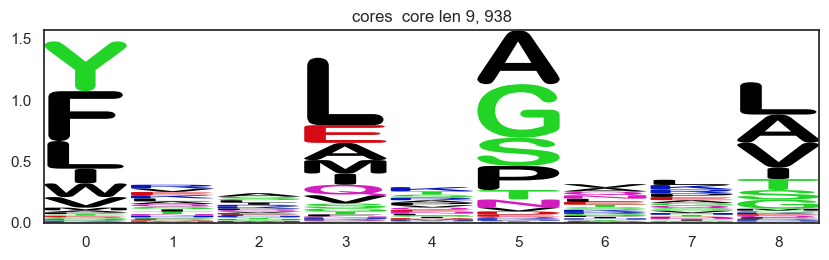

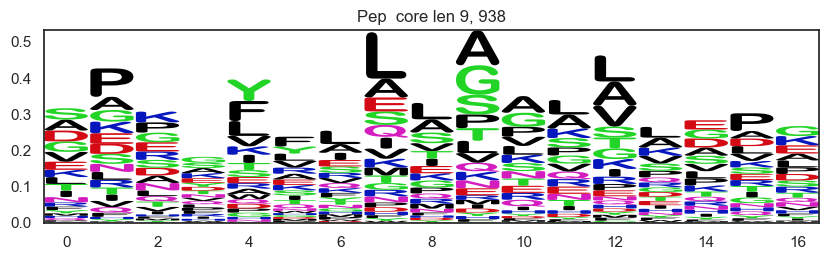

In [14]:
restricted_motif(target_df, core_len=9, use_peptides=True)

C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T


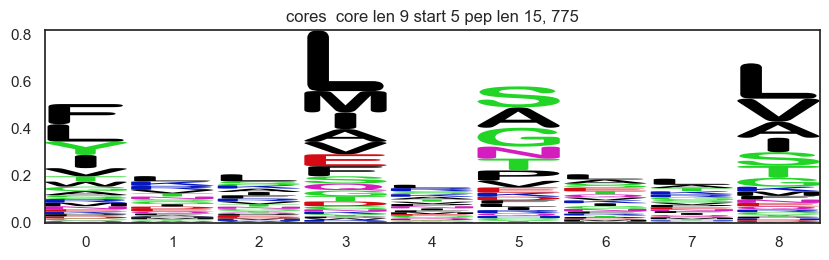

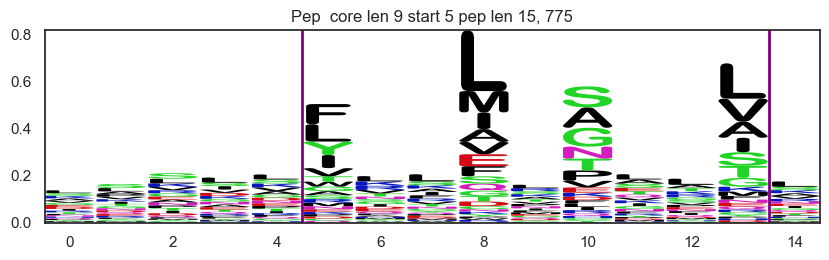

In [33]:
target_peptide_len = 15
target_core_len = 9
core_start = 5
df = restricted_motif(data_df,
                      peptide_len=target_peptide_len, core_len=target_core_len,
                      use_peptides=True,
                      core_start=core_start,mark_left=core_start, mark_right=core_start+target_core_len
                      )


In [41]:
left_parts = df.peptide.str.slice(0, core_start)
right_parts = df.peptide.str.slice(core_start + target_core_len)


In [42]:
right_parts

LAPNTANVQMTFLRL    L
VCGVSAARLTPCGTG    G
VSVTDVTLLMAEHDR    R
GAQELLRVLRAQPVQ    Q
FSTSFYLISIFLHLV    V
                  ..
SKAALTSKLDAAYKL    L
SKNDLSDILKTLTSE    E
LLNNQFGTMPSLTLA    A
YDPDFLRTAVAQVIG    G
NNCTRVEIAEYRRLL    L
Name: peptide, Length: 775, dtype: object

In [43]:
left_parts[left_parts.apply(lambda x: x[1] != 'P')]

LAPNTANVQMTFLRL    LAPNT
VCGVSAARLTPCGTG    VCGVS
VSVTDVTLLMAEHDR    VSVTD
GAQELLRVLRAQPVQ    GAQEL
FSTSFYLISIFLHLV    FSTSF
                   ...  
SKAALTSKLDAAYKL    SKAAL
SKNDLSDILKTLTSE    SKNDL
LLNNQFGTMPSLTLA    LLNNQ
YDPDFLRTAVAQVIG    YDPDF
NNCTRVEIAEYRRLL    NNCTR
Name: peptide, Length: 724, dtype: object

In [44]:
matrix = logomaker.alignment_to_matrix(left_parts.values)
matrix_with_second_p = logomaker.alignment_to_matrix(left_parts[left_parts.apply(lambda x: x[1] == 'P')])
matrix_without_second_p = logomaker.alignment_to_matrix(left_parts[left_parts.apply(lambda x: 'P' not in x[0:core_start] )])

# matrix_without_second_p = logomaker.alignment_to_matrix(left_parts[left_parts.apply(lambda x: x.contains('P'))])
# matrix = logomaker.alignment_to_matrix(right_parts.values)
# matrix_without_second_p = logomaker.alignment_to_matrix(left_parts[left_parts.apply(lambda x: 'P' not in x and 'G' in x)])


C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a n

<AxesSubplot: ylabel='pos'>

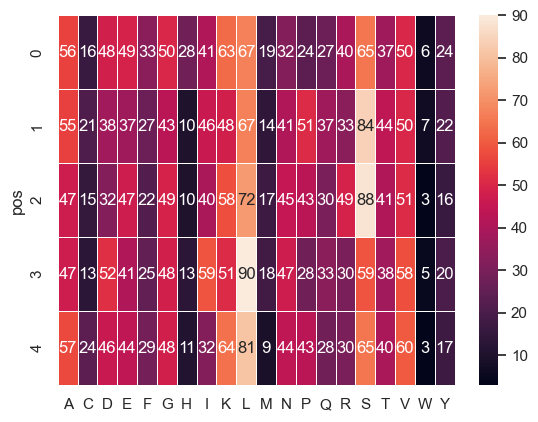

In [45]:
sns.heatmap(matrix, annot=True, linewidth=.5)


<AxesSubplot: ylabel='pos'>

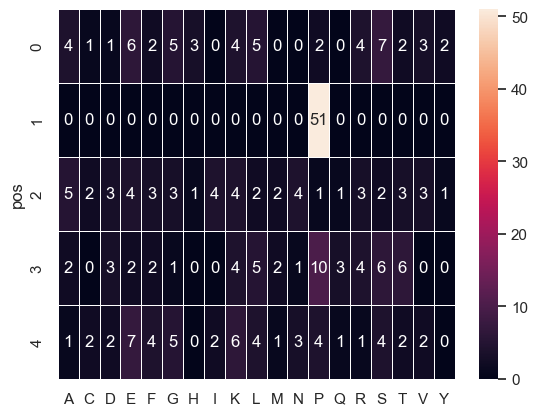

In [46]:
sns.heatmap(matrix_with_second_p, annot=True, linewidth=.5)

<AxesSubplot: ylabel='pos'>

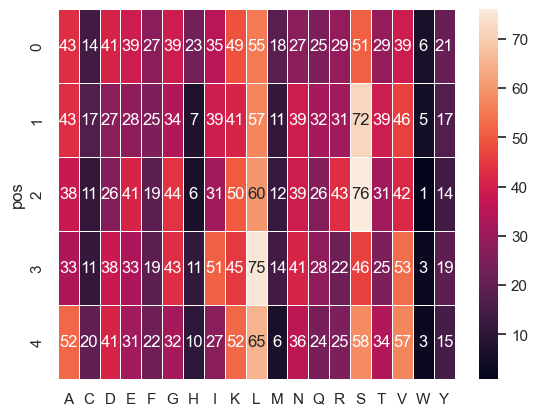

In [47]:
sns.heatmap(matrix_without_second_p, annot=True, linewidth=.5)


In [98]:
left_parts[left_parts.apply(lambda x: 'P' not in x and 'G' in x)]

GALANIAVDKANLEIM    GALAN
DKAGHYLELGAEIART    DKAGH
TAKGLFRAAVPSGAST    TAKGL
EGGKEWAQIFSKHNSG    EGGKE
YGDTVYTIEVPFHGKT    YGDTV
ELGKQYWLITAFHAKG    ELGKQ
DVGSDWRFLRGYHQYA    DVGSD
EQLGEYKFQNALLVRY    EQLGE
SDVGEYRAVTELGRPD    SDVGE
EIGKELEELRARLLPH    EIGKE
HGRQIRMARLLGRDPE    HGRQI
VTSGVGVAGVGVGLLG    VTSGV
TGSEELRSLYNTVATL    TGSEE
KVLGKYISLEGFEQPV    KVLGK
ALAGEFIRASGVEARQ    ALAGE
SVDSGSSEEQGGSSRA    SVDSG
VEVGKFSVLEGQRLVA    VEVGK
ISKGLFAPLQSIQTLH    ISKGL
GVSGTLVLLQGARGFA    GVSGT
GKHFKFTITAGSKVIQ    GKHFK
LNAGAYSKLVQERLVQ    LNAGA
GTTGKFVIFGATSLQN    GTTGK
GGVKKPHRYRPGTVAL    GGVKK
DGVVYYRVQNATLAVA    DGVVY
LKTGKLVSLSAQNLVD    LKTGK
SNGNFIAPEYAYKIVK    SNGNF
NNKGLFQVLAGGTVLQ    NNKGL
EEFGRFASFEAQGALA    EEFGR
EGEGAYEAELAVHLPQ    EGEGA
DAAGQFFPEAAQVAYQ    DAAGQ
KKGDTFSCMVGHEALP    KKGDT
LKTGKLISLSAQNLVD    LKTGK
SAAGRYGAISGFGLSL    SAAGR
GGYVAYSKAATVTGKL    GGYVA
EGKGIYNNIKNFVRFQ    EGKGI
AGKDDYVKALPGQLKP    AGKDD
GAQELLRVLRAQPVQV    GAQEL
GKVDVYGYVVKLRRQR    GKVDV
VDEGIYQLEKGA